# Munich rents: agent-directed investigation of a construction-year reversal

I used the public mboostrs search actions to predict **monthly net rent** for apartments in Munich districts absent from model building. The practical output is a fitted rent prediction for a described apartment. The analytical question is whether the construction-year curve needs an apparent premium for the oldest buildings, and whether an observed variable explains that departure from a generally increasing new-build premium. This is a historical 1999 survey, not a current rent guide. The [upstream `rent99` documentation](https://search.r-project.org/CRAN/refmans/gamlss.data/html/rent99.html) defines rent in euros, area in square metres, `cheating` as central heating, and location as an ordered quality grade.

I chose the next calls after reading training-only outputs. The code below replays those choices with fixed seeds; **no provider made decisions at render time**. The short path reaches a tuned prediction before the longer investigation. The [search methodology](../methodology/search_decisions.ipynb) explains the paired-fold rule and why its standard errors remain descriptive after search.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | Monthly net rent for an apartment in a district not used to fit or choose the model. |
| **Observed response** | `rent`, euros per month. `rentsqm` is excluded because it contains `rent` divided by area. |
| **Estimand** | A conditional mean prediction for the listed apartment characteristics, not an effect of changing construction year or amenities. |
| **Sampling unit** | One surveyed apartment; 3,082 apartments in 336 districts. |
| **Dependence** | Apartments within a district may share unmeasured location and housing conditions. |
| **Split / resampling unit** | Entire district; 269 districts (2,465 apartments) for development and 67 districts (617 apartments) for one final test. |
| **Tuning** | Five grouped folds within development data choose boosting iterations by response-scale MSE; candidates use the same folds. |
| **Uncertainty** | Paired fold standard errors describe development-fold variation, not post-search confidence intervals. One district holdout supplies a predictive check. |
| **Claim type** | Predictive comparison and descriptive shape analysis; no causal or contemporary price claim. |
:::

The decision path is: screen measured predictors → fit and tune a linear baseline → compare smooth shapes → inspect the chosen model → test explanations for the year-curve dip → simplify → score untouched districts once. A candidate enters the model only when it improves the paired-fold score by more than two standard errors, or when a smaller specification stays within two standard errors. These are search preferences, not hypothesis tests; practical gain and support still matter.

## Data and district split

The bundled survey records construction year, floor area, location quality, bathroom and kitchen quality, central heating, and district. I split districts before any response-aware screen. The indicator `old_1918` flags a conspicuous value of the *predictor* `yearc`; it is a candidate representation of a recorded code, not a label learned from rent. `district` defines dependence and is not treated as a numerical predictor of rent in new districts.

In [1]:
import math
import numpy as np
import polars as pl
import altair as alt
from IPython.display import display
import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")
raw = mb.datasets.munich_rent(output="polars")
outer = np.asarray(mb.grouped_folds(
    np.asarray(raw["district"].to_list()), B=5, seed=29))[:, 0]
frame = raw.with_columns(
    (pl.col("location") == 2).cast(pl.Int64).alias("good_location"),
    (pl.col("location") == 3).cast(pl.Int64).alias("top_location"),
    (pl.col("yearc") == 1918).cast(pl.Int64).alias("old_1918"),
).select("rent", "area", "yearc", "old_1918", "good_location",
         "top_location", "bath", "kitchen", "cheating", "district")
train = frame.filter(pl.Series(outer != 0))
test = frame.filter(pl.Series(outer == 0))
print(f"Development: {train.height} apartments, {train['district'].n_unique()} districts")
print(f"Reserved test: {test.height} apartments, {test['district'].n_unique()} districts")

Development: 2465 apartments, 269 districts
Reserved test: 617 apartments, 67 districts


## Training-only screening

`open_search` fixes Gaussian mean prediction, response-scale squared error, five district folds, and a 400-fit whole-workflow budget. Floor area should increase monthly rent; construction year may stand for changing building quality and period; the location grade and amenities are measured predictors, while district is a cluster label. The marginal screen and dual native/neural pre-scan nominate tests without adopting a specification. Their association scores do not adjust for the other predictors.

In [2]:
session = mb.open_search(
    train, "rent", family=mb.Gaussian(), score="mse",
    groups="district", folds=5, seed=31, mstop=100, nu=.3,
    budget=mb.CostBudget(fits=400),
)
session.run("hypothesis", variable="area", role="apartment size",
    statement="Larger apartments should usually have higher monthly rent.",
    would_count_against="A constrained or linear size term predicts materially worse than a flexible alternative.")
session.run("classify")
screen = session.run("column_screen", columns=[
    "area", "yearc", "good_location", "top_location", "bath", "kitchen", "cheating",
])
screen_rows = pl.DataFrame([{
    "variable": row["column"], "linear_r2": row["linear_r2"],
    "curve_r2": row["curve_r2"], "hint": row["hint"],
} for row in screen.value])
display(table(screen_rows, title="Marginal training associations",
    subtitle="Unadjusted R², dimensionless; larger is stronger, not necessarily causal",
    stub="variable", stubhead="Predictor", better={"linear_r2": "max", "curve_r2": "max"},
    labels={"linear_r2": "Linear R²", "curve_r2": "Curve R²", "hint": "Shape hint"},
    notes=("The screen uses development apartments only; correlated predictors can share signal.",)))

GT(_tbl_data=shape: (7, 4)
┌───────────────┬───────────┬──────────┬──────┐
│ variable      ┆ linear_r2 ┆ curve_r2 ┆ hint │
│ ---           ┆ ---       ┆ ---      ┆ ---  │
│ str           ┆ f64       ┆ f64      ┆ str  │
╞═══════════════╪═══════════╪══════════╪══════╡
│ area          ┆ 0.348379  ┆ 0.339559 ┆ line │
│ yearc         ┆ 0.013548  ┆ 0.086282 ┆ step │
│ bath          ┆ 0.058423  ┆ 0.058041 ┆ line │
│ kitchen       ┆ 0.0333    ┆ 0.032907 ┆ line │
│ top_location  ┆ 0.018041  ┆ 0.017642 ┆ line │
│ good_location ┆ 0.008773  ┆ 0.00837  ┆ none │
│ cheating      ┆ 0.054448  ┆ 0.0      ┆ none │
└───────────────┴───────────┴──────────┴──────┘, _body=<great_tables._gt_data.Body object at 0x10cbbeff0>, _boxhead=Boxhead([ColInfo(var='variable', type=<ColInfoTypeEnum.stub: 2>, column_label='variable', column_align='left', column_width=None), ColInfo(var='linear_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Linear R²', column_align='right', column_width=None), ColInfo(var='curve_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Curve R²', column_align='right', column_width=None), ColInfo(var='hint', type=<ColInfoTypeEnum.default: 1>, column_label='Shape hint', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bc2acc0>, _spanners=Spanners([]), _heading=Heading(title='Marginal training associations', subtitle='Unadjusted R², dimensionless; larger is stronger, not necessarily causal', preheader=None), _stubhead='Predictor', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c4fb500>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a5ee540>, _source_notes=['The screen uses development apartments only; correlated predictors can share signal.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10a5eef60>, _formats=[<great_tables._gt_data.FormatInfo object at 0x109fb7980>, <great_tables._gt_data.FormatInfo object at 0x10c46c3b0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10cc31ca0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', typ

In [3]:
scan = session.run("pre_scan", engine="dual", rounds=100)
print("Dual pre-scan priority:", scan.summary["priority"][:7])
print("Area–year pair nominated by:", next(
    row["sources"] for row in scan.summary["pair_sources"]
    if row["columns"] == ["area", "yearc"]
))
print("Native fits charged:", scan.fit_charges)

Dual pre-scan priority: ['area', 'yearc', 'district', 'cheating', 'old_1918', 'kitchen', 'good_location']
Area–year pair nominated by: ['tree']
Native fits charged: 2


Area is the strongest marginal predictor (linear R² about 0.35); year has little linear association (R² about 0.014) but a larger curved/step association (about 0.086). The dual pre-scan also nominates area–year structure. It ranks district highly, but district codes are identifiers and the target is a new district; its fitted effect would not identify an unseen district's rent. I test area and year shapes, rather than accept the pre-scan ranking as a model.

## Linear baseline and first prediction

`bols` fits a linear component for area and year and indicator components for location and amenities. `tune` selects the boosting iteration by five development-district folds, refits on all development apartments, and retains that model. The baseline remains fixed for the final district test.

In [4]:
linear = ("bols(area) + bols(yearc) + bols(good_location) "
          "+ bols(top_location) + bols(bath) + bols(kitchen) "
          "+ bols(cheating)")
session.run("set_spec", rhs=linear)
baseline_tuning = session.run("tune", start=100)
baseline_model = session.model
print("Linear baseline mstop:", baseline_tuning.summary["mstop"])
print("Fits charged by tuning:", baseline_tuning.fit_charges)

Linear baseline mstop: 83
Fits charged by tuning: 6


## Area and construction-year shapes

I compared three revisions at the same 100-iteration limit on the same development folds. A negative change is a reduction in mean squared error (MSE, euros²). `bbs` adds a penalized smooth; it does not itself establish that the shape is stable or causal.

In [5]:
smooth_year = linear.replace("bols(yearc)", "bbs(yearc)")
shapes = session.run("compare", mstop=100, candidates={
    "smooth year": smooth_year,
    "smooth area": linear.replace("bols(area)", "bbs(area)"),
    "both smooth": smooth_year.replace("bols(area)", "bbs(area)"),
})
shape_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in shapes.value])
display(table(shape_rows, title="Initial shape comparison",
    subtitle="District-fold MSE and paired change, euros²; lower is better",
    stub="candidate", stubhead="Specification", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"},
    decimals=1, notes=("Change = candidate minus linear baseline at 100 iterations.",
                       "SE uses five shared development folds and is descriptive after candidate search.")))

GT(_tbl_data=shape: (4, 4)
┌─────────────┬──────────────┬─────────────┬────────────┐
│ candidate   ┆ mse          ┆ change      ┆ se         │
│ ---         ┆ ---          ┆ ---         ┆ ---        │
│ str         ┆ f64          ┆ f64         ┆ f64        │
╞═════════════╪══════════════╪═════════════╪════════════╡
│ current     ┆ 19600.060068 ┆ 0.0         ┆ 0.0        │
│ smooth year ┆ 18626.03535  ┆ -974.024718 ┆ 173.29576  │
│ smooth area ┆ 19735.47783  ┆ 135.417762  ┆ 68.854017  │
│ both smooth ┆ 18707.976306 ┆ -892.083763 ┆ 193.135544 │
└─────────────┴──────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10c46c140>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bc12900>, _spanners=Spanners([]), _heading=Heading(title='Initial shape comparison', subtitle='District-fold MSE and paired change, euros²; lower is better', preheader=None), _stubhead='Specification', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10a0f3e30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cc0ce30>, _source_notes=['Change = candidate minus linear baseline at 100 iterations.', 'SE uses five shared development folds and is descriptive after candidate search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10cc0ca10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10cc338f0>, <great_tables._gt_data.FormatInfo object at 0x111418ef0>, <great_tables._gt_data.FormatInfo object at 0x111419a90>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x11141a5d0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=O

The smooth-year candidate reduces fold MSE by about 974 ± 173 euros²; smoothing area alone raises error by about 135 ± 69 euros². I retain a linear size component and adopt the smooth-year specification. Its own tuning sweep chooses 61 iterations. The two apartment predictions below hold the other recorded characteristics fixed, so they describe the fitted mean and not the effect of rebuilding an apartment.

In [6]:
session.run("adopt", comparison_id=shapes.evidence_id, candidate="smooth year")
smooth_tuning = session.run("tune", start=100)
examples = pl.DataFrame({
    "rent": [0.0, 0.0], "area": [65.0, 65.0],
    "yearc": [1939.0, 1991.0], "old_1918": [0, 0],
    "good_location": [0, 0], "top_location": [0, 0],
    "bath": [0, 0], "kitchen": [0, 0],
    "cheating": [1, 1], "district": [9999, 9999],
})
example_predictions = examples.select("area", "yearc").with_columns(pl.Series(
    "predicted_rent", session.model.predict(examples, type="response")))
display(table(example_predictions, title="Two apartments under the first smooth model",
    subtitle="Predicted monthly net rent, euros; 65 m², average location, standard fittings, heated",
    stub="yearc", stubhead="Construction year", labels={"area": "Area (m²)",
    "predicted_rent": "Predicted rent (€)"}, formats={"predicted_rent": 1},
    notes=("These are conditional model predictions, not renovation or construction effects.",)))

GT(_tbl_data=shape: (2, 3)
┌──────┬────────┬────────────────┐
│ area ┆ yearc  ┆ predicted_rent │
│ ---  ┆ ---    ┆ ---            │
│ f64  ┆ f64    ┆ f64            │
╞══════╪════════╪════════════════╡
│ 65.0 ┆ 1939.0 ┆ 381.343336     │
│ 65.0 ┆ 1991.0 ┆ 556.863233     │
└──────┴────────┴────────────────┘, _body=<great_tables._gt_data.Body object at 0x10a0f3e30>, _boxhead=Boxhead([ColInfo(var='area', type=<ColInfoTypeEnum.default: 1>, column_label='Area (m²)', column_align='right', column_width=None), ColInfo(var='yearc', type=<ColInfoTypeEnum.stub: 2>, column_label='yearc', column_align='right', column_width=None), ColInfo(var='predicted_rent', type=<ColInfoTypeEnum.default: 1>, column_label='Predicted rent (€)', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cb88e30>, _spanners=Spanners([]), _heading=Heading(title='Two apartments under the first smooth model', subtitle='Predicted monthly net rent, euros; 65 m², average location, standard fittings, heated', preheader=None), _stubhead='Construction year', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x111419a30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1114180e0>, _source_notes=['These are conditional model predictions, not renovation or construction effects.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11141a9f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111418920>, <great_tables._gt_data.FormatInfo object at 0x11141abd0>, <great_tables._gt_data.FormatInfo object at 0x111418110>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x11141b0b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category

## Extension: investigating the year curve

The next actions are an exploratory diagnosis of an apparent older-building premium. This extension uses only development apartments and keeps the tuned smooth model as the incumbent unless a rival earns a change. It checks term contribution, common support, a monotone constraint, explicit period coding and nominated interactions. `autospec` is a second opinion rather than the authority for adoption.

In [7]:
proposal = session.run("autospec", budget=20,
    preexploration="native", mstop=80)
print("Autospec proposal:", proposal.summary["formula"])
print("Probe fits reported:", proposal.value.fits)
print("Whole-workflow fits charged for this action:", proposal.fit_charges)

Autospec proposal: rent ~ bbs(area, df=4.0) + bbs(yearc, df=4.0) + bols(old_1918) + bols(good_location) + bols(top_location) + bols(bath) + bols(kitchen) + bols(cheating) + brandom(district, df=4.0)
Probe fits reported: 20
Whole-workflow fits charged for this action: 192


The proposal includes smooth area, the 1918 indicator and a district effect. I do not adopt it: the earlier district-fold comparison did not favor smooth area, the 1918 indicator has not yet earned incremental value, and an effect for a district absent from training is not a usable explanation for that district. The autospec `budget=20` limits its probe allowance; its nested work charged 192 fits to the shared session budget. The difference between a probe allowance and total cost is material here.

In [8]:
contributions = session.run("term_report", shapes=False)
term_rows = pl.DataFrame([{
    "term": row["term"], "gain": row["earns"], "se": row["se"],
} for row in contributions.value.contributions])
display(table(term_rows, title="Terms in the accepted smooth model",
    subtitle="Increase in district-fold MSE if removed and remaining terms refit, euros²; higher gain is better",
    stub="term", stubhead="Term", better={"gain": "max"},
    labels={"gain": "Gain retained", "se": "Paired SE"}, decimals=1,
    notes=("This is a refit contribution, not a causal importance measure.",
           "Bath has the smallest measured contribution: about 77 ± 89 euros².")))

GT(_tbl_data=shape: (7, 3)
┌─────────────────────┬──────────────┬─────────────┐
│ term                ┆ gain         ┆ se          │
│ ---                 ┆ ---          ┆ ---         │
│ str                 ┆ f64          ┆ f64         │
╞═════════════════════╪══════════════╪═════════════╡
│ bols(area)          ┆ 11079.484712 ┆ 1449.699268 │
│ bbs(yearc)          ┆ 2309.629019  ┆ 454.322349  │
│ bols(cheating)      ┆ 1306.653837  ┆ 275.211258  │
│ bols(good_location) ┆ 554.479268   ┆ 71.337718   │
│ bols(top_location)  ┆ 382.814669   ┆ 56.371924   │
│ bols(kitchen)       ┆ 356.565881   ┆ 129.288024  │
│ bols(bath)          ┆ 76.783871    ┆ 89.126747   │
└─────────────────────┴──────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x109fb7980>, _boxhead=Boxhead([ColInfo(var='term', type=<ColInfoTypeEnum.stub: 2>, column_label='term', column_align='left', column_width=None), ColInfo(var='gain', type=<ColInfoTypeEnum.default: 1>, column_label='Gain retained', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cc336b0>, _spanners=Spanners([]), _heading=Heading(title='Terms in the accepted smooth model', subtitle='Increase in district-fold MSE if removed and remaining terms refit, euros²; higher gain is better', preheader=None), _stubhead='Term', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10cc33cb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cc0d6d0>, _source_notes=['This is a refit contribution, not a causal importance measure.', 'Bath has the smallest measured contribution: about 77 ± 89 euros².'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11141ad20>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10ba18ec0>, <great_tables._gt_data.FormatInfo object at 0x111419550>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x11141b410>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', typ

## Construction-year profiles and support

`prediction_profile` replaces construction year over the development population and averages predicted rent. Its `support_fraction_far` reports the fraction of those counterfactual rows far from their observed joint predictor support under a linear support diagnostic. The support frame includes only predictors used by this fitted model. The unused `old_1918` indicator must not remain fixed when year is replaced: doing so would create an artificial support violation. Accumulated local effects (ALE) instead change year within occupied intervals and report interval counts. Neither curve has a post-selection confidence band.

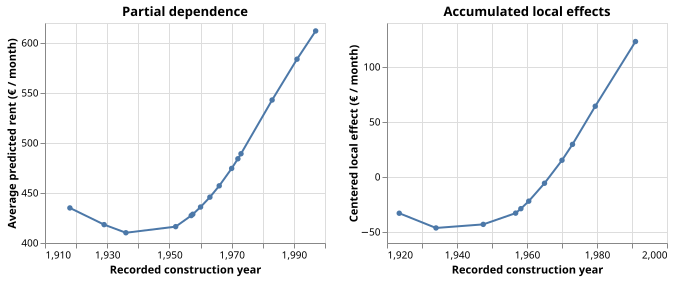

In [9]:
profile_predictors = train.select(
    "area", "yearc", "good_location", "top_location", "bath", "kitchen", "cheating")
profile = mb.prediction_profile(session.model, profile_predictors, "yearc",
    points=18, retain_ice=False)
ale = mb.accumulated_local_effect(session.model, profile_predictors, "yearc", bins=12)
pd_rows = profile.to_frame(output="polars")
ale_rows = ale.to_frame(output="polars")
pd_chart = alt.Chart(pd_rows).mark_line(point=True).encode(
    x=alt.X("grid:Q", title="Recorded construction year"),
    y=alt.Y("average_prediction:Q", title="Average predicted rent (€ / month)",
            scale=alt.Scale(zero=False)),
).properties(title="Partial dependence", width=280, height=220)
ale_chart = alt.Chart(ale_rows).mark_line(point=True).encode(
    x=alt.X("grid:Q", title="Recorded construction year"),
    y=alt.Y("effect:Q", title="Centered local effect (€ / month)"),
    tooltip=["lower:Q", "upper:Q", "n:Q"],
).properties(title="Accumulated local effects", width=280, height=220)
display(alt.hconcat(pd_chart, ale_chart).resolve_scale(y="independent"))

In [10]:
profile_points = pd_rows.filter(
    pl.col("grid").is_in([1918.0, 1929.0, 1936.0, 1997.0])
).with_columns(pl.col("grid").cast(pl.Int64).alias("year")).select(
    "year", "average_prediction", "support_fraction_far")
display(table(profile_points, title="Support at selected construction years",
    subtitle="Predicted euros/month and fraction of replaced rows far from joint support; lower support fraction is better",
    stub="year", stubhead="Recorded year",
    labels={"average_prediction": "Average prediction (€)",
            "support_fraction_far": "Fraction far"},
    formats={"average_prediction": 1, "support_fraction_far": 3},
    notes=("The 1918 support fraction is computed from fitted predictors only; an unused year-derived indicator would inflate it.",
           "The diagnostic uses a linear support model and can miss nonlinear or categorical gaps.")))

GT(_tbl_data=shape: (4, 3)
┌──────┬────────────────────┬──────────────────────┐
│ year ┆ average_prediction ┆ support_fraction_far │
│ ---  ┆ ---                ┆ ---                  │
│ i64  ┆ f64                ┆ f64                  │
╞══════╪════════════════════╪══════════════════════╡
│ 1918 ┆ 435.062392         ┆ 0.073428             │
│ 1929 ┆ 418.367058         ┆ 0.0                  │
│ 1936 ┆ 410.252389         ┆ 0.0                  │
│ 1997 ┆ 612.051331         ┆ 0.151318             │
└──────┴────────────────────┴──────────────────────┘, _body=<great_tables._gt_data.Body object at 0x1110c3b30>, _boxhead=Boxhead([ColInfo(var='year', type=<ColInfoTypeEnum.stub: 2>, column_label='year', column_align='right', column_width=None), ColInfo(var='average_prediction', type=<ColInfoTypeEnum.default: 1>, column_label='Average prediction (€)', column_align='right', column_width=None), ColInfo(var='support_fraction_far', type=<ColInfoTypeEnum.default: 1>, column_label='Fraction far', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11107af60>, _spanners=Spanners([]), _heading=Heading(title='Support at selected construction years', subtitle='Predicted euros/month and fraction of replaced rows far from joint support; lower support fraction is better', preheader=None), _stubhead='Recorded year', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11141a090>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x111419b80>, _source_notes=['The 1918 support fraction is computed from fitted predictors only; an unused year-derived indicator would inflate it.', 'The diagnostic uses a linear support model and can miss nonlinear or categorical gaps.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11141b770>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10a7cb9b0>, <great_tables._gt_data.FormatInfo object at 0x11107aa80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1114669f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='

The fitted mean falls from roughly €435 at the `1918` code to €410 around 1936, then rises toward €612 at 1997. ALE also declines over the two oldest occupied intervals, so global replacement alone does not create the fitted dip. About 7% of the all-apartment replacements at `1918` are flagged far after restricting the diagnostic to fitted predictors, so simple linear joint-support failure does not account for the dip. The distribution has 355 development apartments at exactly 1918 and 298 at 1957.5; those heaps, including a fractional year, suggest that `yearc` may encode grouped periods. That is an inference from the values, not a documented recoding rule. Older apartments also differ in size, location grade and heating. The dip is a reason to test alternatives, not proof of an omitted cause.

In [11]:
eras = train.with_columns(
    pl.when(pl.col("yearc") == 1918).then(pl.lit("1918 code"))
      .when(pl.col("yearc") < 1950).then(pl.lit("1919–49"))
      .when(pl.col("yearc") < 1970).then(pl.lit("1950–69"))
      .when(pl.col("yearc") < 1990).then(pl.lit("1970–89"))
      .otherwise(pl.lit("1990–97")).alias("period")
)
support = eras.group_by("period").agg(
    pl.len().alias("apartments"), pl.col("district").n_unique().alias("districts"),
    pl.col("area").mean().alias("area_m2"),
    (1 - pl.col("cheating").mean()).alias("without_heating"),
).sort("period")
display(table(support, title="Observed support by construction period",
    subtitle="Development apartments, distinct districts, mean area (m²), and share without central heating",
    stub="period", stubhead="Recorded period",
    labels={"apartments": "Apartments", "districts": "Districts",
            "area_m2": "Mean area (m²)", "without_heating": "No heating share"},
    formats={"area_m2": 1, "without_heating": 3},
    notes=("Period bands are descriptive; the model uses recorded year, not these bands.",)))

GT(_tbl_data=shape: (5, 5)
┌───────────┬────────────┬───────────┬───────────┬─────────────────┐
│ period    ┆ apartments ┆ districts ┆ area_m2   ┆ without_heating │
│ ---       ┆ ---        ┆ ---       ┆ ---       ┆ ---             │
│ str       ┆ u32        ┆ u32       ┆ f64       ┆ f64             │
╞═══════════╪════════════╪═══════════╪═══════════╪═════════════════╡
│ 1918 code ┆ 355        ┆ 104       ┆ 81.715493 ┆ 0.321127        │
│ 1919–49   ┆ 362        ┆ 120       ┆ 73.455801 ┆ 0.196133        │
│ 1950–69   ┆ 997        ┆ 196       ┆ 63.107322 ┆ 0.058175        │
│ 1970–89   ┆ 596        ┆ 190       ┆ 63.087248 ┆ 0.008389        │
│ 1990–97   ┆ 155        ┆ 99        ┆ 66.509677 ┆ 0.0             │
└───────────┴────────────┴───────────┴───────────┴─────────────────┘, _body=<great_tables._gt_data.Body object at 0x11141a120>, _boxhead=Boxhead([ColInfo(var='period', type=<ColInfoTypeEnum.stub: 2>, column_label='period', column_align='left', column_width=None), ColInfo(var='apartments', type=<ColInfoTypeEnum.default: 1>, column_label='Apartments', column_align='right', column_width=None), ColInfo(var='districts', type=<ColInfoTypeEnum.default: 1>, column_label='Districts', column_align='right', column_width=None), ColInfo(var='area_m2', type=<ColInfoTypeEnum.default: 1>, column_label='Mean area (m²)', column_align='right', column_width=None), ColInfo(var='without_heating', type=<ColInfoTypeEnum.default: 1>, column_label='No heating share', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cc0c6e0>, _spanners=Spanners([]), _heading=Heading(title='Observed support by construction period', subtitle='Development apartments, distinct districts, mean area (m²), and share without central heating', preheader=None), _stubhead='Recorded period', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10a7ebd70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109fb7980>, _source_notes=['Period bands are descriptive; the model uses recorded year, not these bands.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111466f90>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10cc0cf20>, <great_tables._gt_data.FormatInfo object at 0x111465790>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1114669f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(sc

## Monotonicity and period coding

I recorded two competing explanations: a newer-building premium with an old-period exception, and a data-code explanation concentrated at 1918. A monotone year term tests whether the exception is needed for prediction. Adding `old_1918` to that term asks whether a separate oldest-code premium improves it. A linear year plus that indicator tests whether the smooth was only hiding one jump. All comparisons keep the original development folds and the tuned 61-iteration limit.

In [12]:
session.run("hypothesis", variable="yearc", role="building-period and quality proxy",
    statement="Rent generally rises with newer construction, apart from a possible older-building premium.",
    would_count_against="A monotone year term predicts as well on new-district folds.")
session.run("hypothesis", variable="old_1918", role="possible period code",
    statement="The oldest-year departure may be concentrated at the heaped 1918 code.",
    would_count_against="An explicit 1918 indicator does not improve a monotone or linear year model.")
current = session.spec
period_tests = session.run("compare", candidates={
    "monotone year": current.replace("bbs(yearc)",
        'bmono(yearc, constraint="increasing")'),
    "monotone plus 1918": current.replace("bbs(yearc)",
        'bmono(yearc, constraint="increasing") + bols(old_1918)'),
    "linear plus 1918": current.replace("bbs(yearc)",
        "bols(yearc) + bols(old_1918)"),
})
period_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in period_tests.value])
display(table(period_rows, title="Construction-year alternatives",
    subtitle="New-district development-fold MSE and change from incumbent, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("All candidates are fitted at the incumbent's 61 iterations on the same folds.",
           "The standard errors are descriptive after this search.")))

GT(_tbl_data=shape: (4, 4)
┌────────────────────┬──────────────┬────────────┬────────────┐
│ candidate          ┆ mse          ┆ change     ┆ se         │
│ ---                ┆ ---          ┆ ---        ┆ ---        │
│ str                ┆ f64          ┆ f64        ┆ f64        │
╞════════════════════╪══════════════╪════════════╪════════════╡
│ current            ┆ 18615.140114 ┆ 0.0        ┆ 0.0        │
│ monotone year      ┆ 18632.567901 ┆ 17.427788  ┆ 51.18843   │
│ monotone plus 1918 ┆ 18639.797222 ┆ 24.657109  ┆ 39.1508    │
│ linear plus 1918   ┆ 19284.884466 ┆ 669.744352 ┆ 135.351577 │
└────────────────────┴──────────────┴────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x109fb7980>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1110c18b0>, _spanners=Spanners([]), _heading=Heading(title='Construction-year alternatives', subtitle='New-district development-fold MSE and change from incumbent, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10cc0d4f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cc0c770>, _source_notes=["All candidates are fitted at the incumbent's 61 iterations on the same folds.", 'The standard errors are descriptive after this search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11107b830>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10a5ee540>, <great_tables._gt_data.FormatInfo object at 0x111467740>, <great_tables._gt_data.FormatInfo object at 0x111466ae0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1114671d0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=T

The monotone fit is only about 17 ± 51 euros² worse than the smooth: this search does not establish that the old-period dip is necessary. Adding a 1918 indicator to the monotone fit does not improve it. A linear year with only that indicator is roughly 670 ± 135 euros² worse, so the year structure is broader than a single heaped code. I keep the already accepted smooth while treating its old-period dip as uncertain.

## Residual interaction leads

`interaction_screen` inspects response residuals from the accepted model. It ranks area–year first, so I compare a tensor and a shallow tree on that pair. Because heating is uncommon among newer apartments, I also test whether a year-by-heating effect explains the old-period pattern and inspect its support before considering adoption.

In [13]:
leads = session.run("interaction_screen")
lead_rows = pl.DataFrame([{
    "pair": f"{row['left']} × {row['right']}", "screen_gain": row["removed"],
} for row in leads.summary["top_pairs"][:5]])
display(table(lead_rows, title="Residual interaction nominations",
    subtitle="Half-split residual MSE removed, euros²; nomination only, higher is stronger",
    stub="pair", stubhead="Pair", labels={"screen_gain": "Screen signal"},
    better={"screen_gain": "max"}, decimals=1,
    notes=("This ranking is not a fold-tested improvement; complete candidates follow below.",)))

interaction_tests = session.run("compare", candidates={
    "area–year tensor": current + " + bbs(area) %X% bbs(yearc)",
    "year by heating": current + " + bbs(yearc, by=cheating)",
    "shallow area–year tree": current + " + btree(area, yearc, maxdepth=2)",
})
interaction_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in interaction_tests.value])
display(table(interaction_rows, title="Complete interaction specifications",
    subtitle="New-district development-fold MSE and change from additive model, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("The tensor and tree test the nominated area–year pair; the heating term tests a domain hypothesis.",
           "The apparent 1918 premium remains a conditional association, not a heating effect.")))

GT(_tbl_data=shape: (5, 2)
┌─────────────────────────┬─────────────┐
│ pair                    ┆ screen_gain │
│ ---                     ┆ ---         │
│ str                     ┆ f64         │
╞═════════════════════════╪═════════════╡
│ area × cheating         ┆ 158.07388   │
│ old_1918 × bath         ┆ 143.163588  │
│ good_location × kitchen ┆ 49.93101    │
│ old_1918 × kitchen      ┆ 34.331142   │
│ old_1918 × cheating     ┆ 18.184374   │
└─────────────────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10c46c140>, _boxhead=Boxhead([ColInfo(var='pair', type=<ColInfoTypeEnum.stub: 2>, column_label='pair', column_align='left', column_width=None), ColInfo(var='screen_gain', type=<ColInfoTypeEnum.default: 1>, column_label='Screen signal', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x111467860>, _spanners=Spanners([]), _heading=Heading(title='Residual interaction nominations', subtitle='Half-split residual MSE removed, euros²; nomination only, higher is stronger', preheader=None), _stubhead='Pair', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11107b830>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11107b770>, _source_notes=['This ranking is not a fold-tested improvement; complete candidates follow below.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111450ce0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111450c20>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x111450d10>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table',

GT(_tbl_data=shape: (4, 4)
┌────────────────────────┬──────────────┬─────────────┬────────────┐
│ candidate              ┆ mse          ┆ change      ┆ se         │
│ ---                    ┆ ---          ┆ ---         ┆ ---        │
│ str                    ┆ f64          ┆ f64         ┆ f64        │
╞════════════════════════╪══════════════╪═════════════╪════════════╡
│ current                ┆ 18615.140114 ┆ 0.0         ┆ 0.0        │
│ area–year tensor       ┆ 18542.524844 ┆ -72.61527   ┆ 194.938428 │
│ year by heating        ┆ 18570.985788 ┆ -44.154326  ┆ 14.765109  │
│ shallow area–year tree ┆ 19927.516112 ┆ 1312.375998 ┆ 590.62867  │
└────────────────────────┴──────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10cc31ca0>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a7e8aa0>, _spanners=Spanners([]), _heading=Heading(title='Complete interaction specifications', subtitle='New-district development-fold MSE and change from additive model, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1110c0800>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11141be00>, _source_notes=['The tensor and tree test the nominated area–year pair; the heating term tests a domain hypothesis.', 'The apparent 1918 premium remains a conditional association, not a heating effect.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11141ae40>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111451940>, <great_tables._gt_data.FormatInfo object at 0x1114520c0>, <great_tables._gt_data.FormatInfo object at 0x111453860>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1114532c0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=Options

The area–year tensor improves MSE by about 73 ± 195 euros², too unstable for adoption; the shallow tree worsens it. The heating interaction improves it by about 33 ± 16 euros², just over the two-SE search threshold, but changes fold RMSE by only about €0.12/month. In the development sample, 32% of the 1918-code apartments lack central heating, while none of the 1990–97 apartments do. A curve for recent unheated apartments would extrapolate beyond observed combinations. I do not add that weakly supported interaction. The measured alternatives explain why a selected curve should prompt tests, not a confident latent-factor story.

## A smaller accepted model

The contribution report makes premium bathroom the least stable term. I compare removing bathroom and kitchen separately. `adopt(..., simplification_se=2)` allows a smaller model when its fold error increase stays within two paired standard errors; the rule does not assert equivalence.

In [14]:
simplifications = session.run("compare", candidates={
    "drop bath": current.replace(" + bols(bath)", ""),
    "drop kitchen": current.replace(" + bols(kitchen)", ""),
})
simple_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in simplifications.value])
display(table(simple_rows, title="One-term reductions",
    subtitle="New-district development-fold MSE and change, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("Positive change means the smaller model predicts worse on these folds.",
           "The two-SE tolerance is a descriptive parsimony rule, not an equivalence test.")))

GT(_tbl_data=shape: (3, 4)
┌──────────────┬──────────────┬────────────┬────────────┐
│ candidate    ┆ mse          ┆ change     ┆ se         │
│ ---          ┆ ---          ┆ ---        ┆ ---        │
│ str          ┆ f64          ┆ f64        ┆ f64        │
╞══════════════╪══════════════╪════════════╪════════════╡
│ current      ┆ 18615.140114 ┆ 0.0        ┆ 0.0        │
│ drop bath    ┆ 18691.923984 ┆ 76.783871  ┆ 89.126747  │
│ drop kitchen ┆ 18971.705995 ┆ 356.565881 ┆ 129.288024 │
└──────────────┴──────────────┴────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10c46c140>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1111152b0>, _spanners=Spanners([]), _heading=Heading(title='One-term reductions', subtitle='New-district development-fold MSE and change, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x111465400>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x111467860>, _source_notes=['Positive change means the smaller model predicts worse on these folds.', 'The two-SE tolerance is a descriptive parsimony rule, not an equivalence test.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111465b50>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111467cb0>, <great_tables._gt_data.FormatInfo object at 0x111465e20>, <great_tables._gt_data.FormatInfo object at 0x11141bc80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x111418c80>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px'

Dropping bath costs about 77 ± 89 euros² and meets the stated parsimony tolerance. Dropping kitchen costs about 357 ± 129 euros², so I retain it. The final specification keeps a linear area term, a smooth construction-year term, location quality, kitchen quality and central heating. I retune the smaller model rather than reuse the previous stopping iteration.

In [15]:
session.run("adopt", comparison_id=simplifications.evidence_id,
            candidate="drop bath", simplification_se=2.0)
final_tuning = session.run("tune", start=100)
final_cv = session.run("evaluate", mstop=session.mstop)
print("Accepted specification:", session.spec)
print("Tuned mstop:", session.mstop)
print(f"Development-fold MSE: {final_cv.summary['score']:.1f} euros²")
print("Whole-workflow native fits charged:", session.state()["budget"]["fit_charges"])
print("Action sequence:", " → ".join(row.action for row in session.evidence))

Accepted specification: bols(area) + bbs(yearc) + bols(good_location) + bols(top_location) + bols(kitchen) + bols(cheating)
Tuned mstop: 56
Development-fold MSE: 18683.9 euros²
Whole-workflow native fits charged: 332
Action sequence: hypothesis → classify → column_screen → pre_scan → set_spec → tune → compare → adopt → tune → autospec → term_report → hypothesis → hypothesis → compare → interaction_screen → compare → compare → adopt → tune → evaluate


## One-time district test

The selected model and the separately tuned linear baseline are frozen before either sees test outcomes. `final_evaluate` reads the 67 held-out districts once for the selected specification. The baseline's predictions were fixed on development data; its error is calculated in this same reporting step. No later model choice uses these results.

In [16]:
session.run("freeze")
final_test = session.run("final_evaluate", data=test)
linear_pred = baseline_model.predict(test, type="response")
linear_mse = pl.DataFrame({"observed": test["rent"],
                           "predicted": pl.Series(linear_pred)}).select(
    ((pl.col("observed") - pl.col("predicted")) ** 2).mean()).item()
test_rows = pl.DataFrame([
    {"model": "Tuned linear baseline", "mse": linear_mse,
     "rmse": math.sqrt(linear_mse)},
    {"model": "Selected smaller smooth model", "mse": final_test.summary["score"],
     "rmse": math.sqrt(final_test.summary["score"])},
])
display(table(test_rows, title="Untouched-district prediction",
    subtitle="617 apartments in 67 held-out districts; MSE in euros², RMSE in euros/month; lower is better",
    stub="model", stubhead="Frozen model", better={"mse": "min", "rmse": "min"},
    labels={"mse": "MSE", "rmse": "RMSE"}, decimals=1,
    notes=("Both specifications and stopping iterations were fixed using development districts.",
           "This one district split is a predictive check, not a confidence interval for the search procedure.")))

GT(_tbl_data=shape: (2, 3)
┌───────────────────────────────┬──────────────┬────────────┐
│ model                         ┆ mse          ┆ rmse       │
│ ---                           ┆ ---          ┆ ---        │
│ str                           ┆ f64          ┆ f64        │
╞═══════════════════════════════╪══════════════╪════════════╡
│ Tuned linear baseline         ┆ 21041.358205 ┆ 145.056397 │
│ Selected smaller smooth model ┆ 20526.963292 ┆ 143.27234  │
└───────────────────────────────┴──────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10c46c140>, _boxhead=Boxhead([ColInfo(var='model', type=<ColInfoTypeEnum.stub: 2>, column_label='model', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='rmse', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11141ad80>, _spanners=Spanners([]), _heading=Heading(title='Untouched-district prediction', subtitle='617 apartments in 67 held-out districts; MSE in euros², RMSE in euros/month; lower is better', preheader=None), _stubhead='Frozen model', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10a7cb9b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11107b770>, _source_notes=['Both specifications and stopping iterations were fixed using development districts.', 'This one district split is a predictive check, not a confidence interval for the search procedure.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11141bd70>, _formats=[<great_tables._gt_data.FormatInfo object at 0x111453ef0>, <great_tables._gt_data.FormatInfo object at 0x111451af0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1114532c0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=Option

The selected model's test RMSE is about €143.3/month versus €145.1/month for the tuned linear baseline, a small improvement on this one district split. It does not establish that the detailed old-building dip or any interaction generalizes. The year curve is conditional on a coarse location grade and recorded amenities; unmeasured renovation, exact location and period coding remain plausible explanations. `rentsqm` was excluded because it is derived from rent, and the district effect was excluded because the target districts were unseen. The same procedure would need repeated district holdouts before claiming a stable advantage over a simpler pricing rule.

Related cases model [spatial district effects](munich_rents.ipynb) and [the conditional rent distribution](munich_rents_distributional.ipynb). This study records analyst-chosen search actions. The interaction comparison and year-curve checks show how small gains and limited support can restrict the interpretation of a selected shape.